# Exploratory Data Analysis & Statistical Insights
**Goal:** uncover hidden business patterns in customer data using descriptive statistics, distributions, correlation matrices and hypothesis tests.

**Dataset:** 2,000 customers (synthetic, seeded for reproducibility) with demographics, acquisition channel, spend, discount rate, support tickets, satisfaction and a `retained` flag.

**Contents**
1. Setup & data
2. Summary descriptive statistics
3. Visual exploration: histograms, box plots, correlation heatmap
4. Hypothesis tests (3)
5. Top 5 critical findings

## 1. Setup & data

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi":110, "axes.titleweight":"bold"})

# ---- Synthetic customer dataset (seeded) ----
rng = np.random.default_rng(42)
n = 2000
segment = rng.choice(["Budget","Standard","Premium"], n, p=[.40,.40,.20])
region  = rng.choice(["North","South","East","West"], n, p=[.25,.30,.25,.20])
channel = rng.choice(["Organic","Paid Ads","Email","Referral"], n, p=[.35,.30,.20,.15])
age     = np.clip(rng.normal(34,10,n),18,70).round().astype(int)
tenure  = np.clip(rng.gamma(2.2,9,n),1,72).round().astype(int)
discount= np.clip(rng.beta(2,6,n)*40,0,40).round(1)
base    = {"Budget":45,"Standard":90,"Premium":180}
spend   = np.array([rng.lognormal(np.log(base[s]),0.35) for s in segment]).round(2)
orders  = np.clip(rng.poisson(2.2+0.01*tenure+0.002*spend,n),0,15)
tickets = rng.poisson(np.where(channel=="Paid Ads",1.8,1.1),n)
sat     = np.clip(4.1-0.28*tickets+rng.normal(0,0.7,n),1,5).round(1)
logit   = (-0.2+0.035*tenure+0.35*(sat-3.5)-0.02*discount
           +0.4*(segment=="Premium")+0.25*(channel=="Referral")-0.15*(channel=="Paid Ads"))
retained = (rng.random(n) < 1/(1+np.exp(-logit))).astype(int)
spend[rng.choice(n,12,replace=False)] *= rng.uniform(4,7,12)   # a few extreme spenders

df = pd.DataFrame(dict(customer_id=[f"C{i:04d}" for i in range(n)], age=age, region=region,
    segment=segment, channel=channel, tenure_months=tenure, discount_rate=discount,
    monthly_spend=spend.round(2), orders_per_month=orders, support_tickets=tickets,
    satisfaction=sat, retained=retained))
df.loc[rng.choice(n,40,replace=False),"satisfaction"] = np.nan   # missing survey responses

num_cols = ["age","tenure_months","discount_rate","monthly_spend","orders_per_month","support_tickets","satisfaction"]
print(df.shape); df.head()

(2000, 12)


,customer_id,age,region,segment,channel,tenure_months,discount_rate,monthly_spend,orders_per_month,support_tickets,satisfaction,retained
0,C0000,24,West,Standard,Email,7,7.2,65.21,1,2,4.4,1
1,C0001,39,South,Standard,Paid Ads,6,21.1,83.07,2,0,3.6,0
2,C0002,28,West,Premium,Referral,15,7.9,354.89,4,0,3.4,1
3,C0003,18,East,Standard,Organic,30,11.3,129.64,4,1,3.0,1
4,C0004,31,North,Budget,Paid Ads,34,10.1,50.12,2,1,2.9,0


In [2]:
print(df.dtypes.to_string()); print("\nMissing values:\n", df.isna().sum()[df.isna().sum()>0].to_string())
print(f"\nOverall retention rate: {df.retained.mean():.1%}")

customer_id             str
age                   int64
region                  str
segment                 str
channel                 str
tenure_months         int64
discount_rate       float64
monthly_spend       float64
orders_per_month      int64
support_tickets       int64
satisfaction        float64
retained              int64

Missing values:
 satisfaction    40

Overall retention rate: 58.2%


## 2. Summary descriptive statistics

In [3]:
desc = df[num_cols].describe(percentiles=[.25,.5,.75]).T
desc["median"] = df[num_cols].median()
desc["skew"]   = df[num_cols].skew()
desc[["count","mean","median","std","min","25%","50%","75%","max","skew"]].round(2)

,count,mean,median,std,min,25%,50%,75%,max,skew
age,2000.0,34.25,34.00,9.58,18.00,28.00,34.00,41.00,67.0,0.28
tenure_months,2000.0,19.56,17.00,13.21,1.00,10.00,17.00,26.00,72.0,1.19
discount_rate,2000.0,9.81,9.00,5.76,0.30,5.30,9.00,13.30,33.5,0.72
monthly_spend,2000.0,100.11,77.25,82.71,17.29,49.44,77.25,126.62,1648.6,5.73
orders_per_month,2000.0,2.61,2.00,1.65,0.00,1.00,2.00,4.00,10.0,0.70
support_tickets,2000.0,1.29,1.00,1.19,0.00,0.00,1.00,2.00,6.0,1.02
satisfaction,1960.0,3.71,3.70,0.73,1.00,3.20,3.70,4.20,5.0,-0.22


In [4]:
# Segment-level view
df.groupby("segment").agg(customers=("customer_id","count"), mean_spend=("monthly_spend","mean"),
    median_spend=("monthly_spend","median"), retention=("retained","mean"),
    avg_discount=("discount_rate","mean"), avg_satisfaction=("satisfaction","mean")).round(2)

,customers,mean_spend,median_spend,retention,avg_discount,avg_satisfaction
segment,,,,,,
Budget,789,49.04,44.74,0.56,9.56,3.72
Premium,413,201.40,183.25,0.68,9.93,3.72
Standard,798,98.18,91.22,0.55,10.00,3.70


**Reading the table:** monthly spend has a mean well above its median and a very high skew, so a handful of extreme spenders pull the average up. Median is the safer summary for spend. Satisfaction is missing for 2% of customers (40 rows), which are excluded only from analyses that use it.

## 3. Visual exploration

### 3.1 Histogram distributions

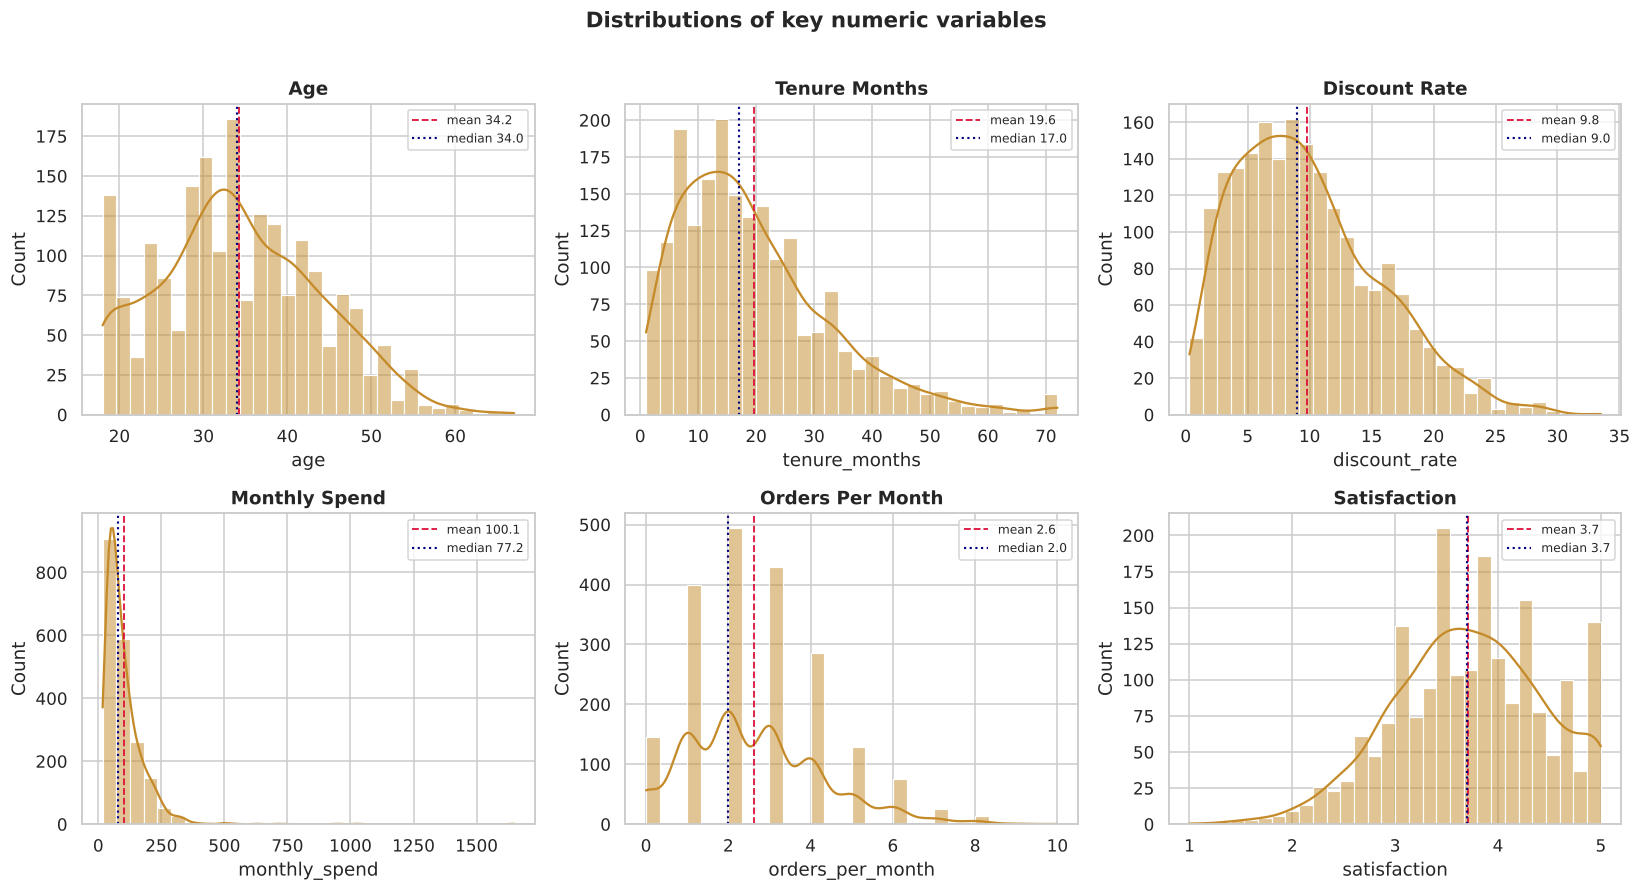

In [5]:
fig, axes = plt.subplots(2,3, figsize=(15,8))
for ax,c in zip(axes.ravel(), ["age","tenure_months","discount_rate","monthly_spend","orders_per_month","satisfaction"]):
    sns.histplot(df[c], kde=True, bins=30, ax=ax, color="#C58B2A")
    ax.axvline(df[c].mean(), color="crimson", ls="--", lw=1.2, label=f"mean {df[c].mean():.1f}")
    ax.axvline(df[c].median(), color="navy", ls=":", lw=1.4, label=f"median {df[c].median():.1f}")
    ax.set_title(c.replace("_"," ").title()); ax.legend(fontsize=8)
plt.suptitle("Distributions of key numeric variables", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

### 3.2 Box plots & anomaly detection (IQR rule)

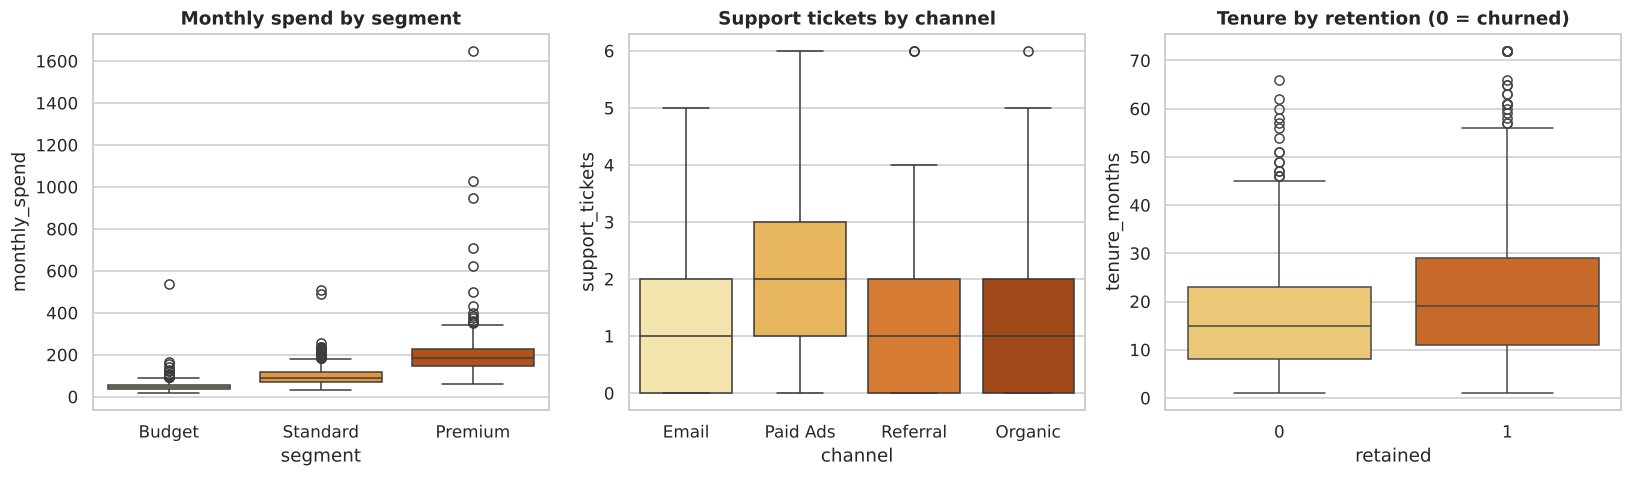

,IQR outliers,share_%
age,7,0.35
tenure_months,63,3.15
discount_rate,21,1.05
monthly_spend,86,4.30
orders_per_month,3,0.15
support_tickets,9,0.45
satisfaction,12,0.60


In [6]:
fig, axes = plt.subplots(1,3, figsize=(15,4.5))
sns.boxplot(data=df, x="segment", y="monthly_spend", order=["Budget","Standard","Premium"], palette="YlOrBr", ax=axes[0])
axes[0].set_title("Monthly spend by segment")
sns.boxplot(data=df, x="channel", y="support_tickets", palette="YlOrBr", ax=axes[1]); axes[1].set_title("Support tickets by channel")
sns.boxplot(data=df, x="retained", y="tenure_months", palette="YlOrBr", ax=axes[2]); axes[2].set_title("Tenure by retention (0 = churned)")
plt.tight_layout(); plt.show()

def iqr_outliers(s):
    q1,q3 = s.quantile([.25,.75]); i = q3-q1
    return ((s < q1-1.5*i) | (s > q3+1.5*i))
out = pd.DataFrame({c: [iqr_outliers(df[c].dropna()).sum()] for c in num_cols}, index=["IQR outliers"]).T
out["share_%"] = (out["IQR outliers"]/len(df)*100).round(2); out

In [7]:
# Extreme spend anomalies (> 3x the segment's 99th pct would be overkill; show the top 12)
df.nlargest(12,"monthly_spend")[["customer_id","segment","monthly_spend","orders_per_month","retained"]]

,customer_id,segment,monthly_spend,orders_per_month,retained
1265,C1265,Premium,1648.60,7,1
779,C0779,Premium,1026.69,1,1
980,C0980,Premium,944.75,3,0
1134,C1134,Premium,710.58,6,1
166,C0166,Premium,624.96,3,0
124,C0124,Budget,538.06,6,0
1611,C1611,Standard,507.72,4,1
245,C0245,Premium,500.67,3,1
791,C0791,Standard,489.24,3,0
82,C0082,Premium,434.71,3,1


### 3.3 Correlation heatmap

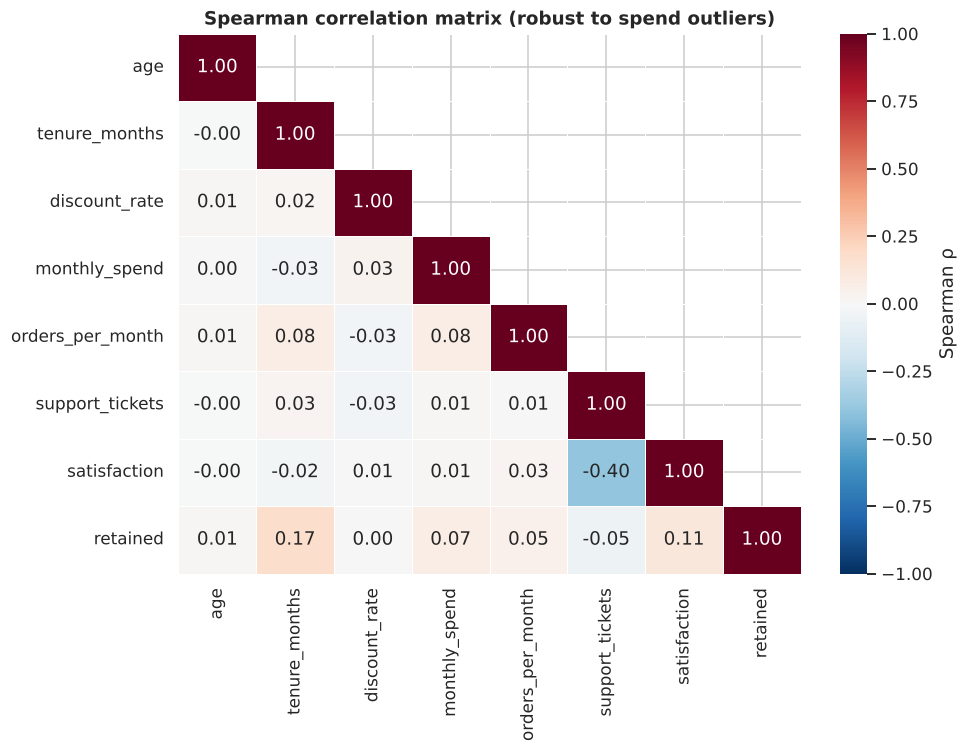

tenure_months       0.175
satisfaction        0.114
monthly_spend       0.073
support_tickets    -0.049
orders_per_month    0.047
age                 0.010
discount_rate       0.002
Name: retained, dtype: float64

In [8]:
corr = df[num_cols+["retained"]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(9,7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5, cbar_kws={"label":"Spearman ρ"})
plt.title("Spearman correlation matrix (robust to spend outliers)"); plt.tight_layout(); plt.show()
corr["retained"].drop("retained").sort_values(key=abs, ascending=False).round(3)

**Takeaways:** spend, orders and tenure show mild positive relationships. The notable negative link is **support tickets ↔ satisfaction**. Discount rate has essentially zero correlation with retention. Spearman is used because spend is heavily skewed.

## 4. Hypothesis tests
Significance level α = 0.05. Each test states H₀/H₁, the test used, and the business interpretation.

### H1: Higher discount rates improve customer retention
- **H₀:** mean discount rate is equal for retained and churned customers
- **H₁:** the means differ
- **Tests:** Welch t-test, point-biserial correlation, and a logistic regression controlling for tenure, satisfaction and tickets

Mean discount: retained 9.81%  vs churned 9.83%
Welch t = -0.074, p = 0.9408
Point-biserial r = -0.0017, p = 0.9407

Logistic regression (outcome = retained):
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -1.5281      0.318     -4.802      0.000      -2.152      -0.904
tenure_months       0.0304      0.004      7.784      0.000       0.023       0.038
discount_rate      -0.0030      0.008     -0.362      0.717      -0.019       0.013
satisfaction        0.3588      0.072      5.009      0.000       0.218       0.499
support_tickets    -0.0090      0.044     -0.207      0.836      -0.095       0.077


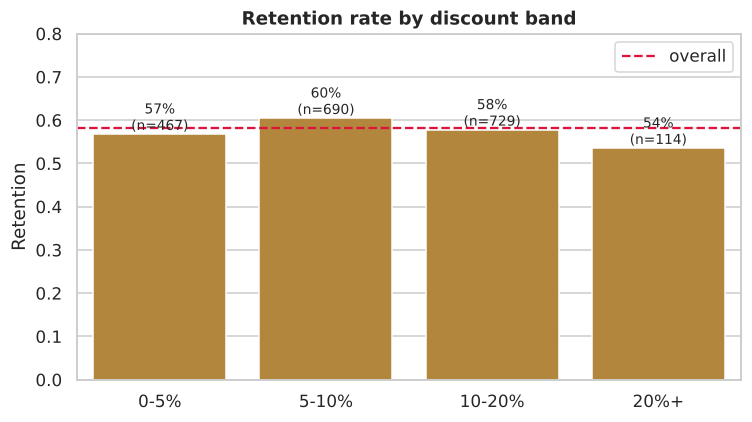

In [9]:
ret, chn = df[df.retained==1].discount_rate, df[df.retained==0].discount_rate
t = stats.ttest_ind(ret, chn, equal_var=False)
pb = stats.pointbiserialr(df.retained, df.discount_rate)
print(f"Mean discount: retained {ret.mean():.2f}%  vs churned {chn.mean():.2f}%")
print(f"Welch t = {t.statistic:.3f}, p = {t.pvalue:.4f}")
print(f"Point-biserial r = {pb.statistic:.4f}, p = {pb.pvalue:.4f}")

d = df.dropna(subset=["satisfaction"])
X = sm.add_constant(d[["tenure_months","discount_rate","satisfaction","support_tickets"]])
logit_m = sm.Logit(d.retained, X).fit(disp=0)
print("\nLogistic regression (outcome = retained):")
print(logit_m.summary().tables[1])

df["discount_band"] = pd.cut(df.discount_rate, [-.1,5,10,20,41], labels=["0-5%","5-10%","10-20%","20%+"])
rate = df.groupby("discount_band", observed=True).retained.agg(["mean","count"]).reset_index()
fig, ax = plt.subplots(figsize=(7,4))
sns.barplot(data=rate, x="discount_band", y="mean", color="#C58B2A", ax=ax)
for i,r in rate.iterrows(): ax.text(i, r["mean"]+0.01, f"{r['mean']:.0%}\n(n={r['count']})", ha="center", fontsize=9)
ax.axhline(df.retained.mean(), color="crimson", ls="--", label="overall"); ax.set_ylim(0,0.8); ax.legend()
ax.set_title("Retention rate by discount band"); ax.set_ylabel("Retention"); ax.set_xlabel(""); plt.tight_layout(); plt.show()

**Result:** fail to reject H₀ (p ≈ 0.94). Retained and churned customers received virtually identical discounts, and the effect stays non-significant after controlling for tenure and satisfaction. **Deeper discounts are not buying loyalty.** The 20%+ band actually retains slightly worse than average.

### H2: Retention differs by acquisition channel
- **H₀:** channel and retention are independent
- **H₁:** retention rate depends on channel
- **Test:** chi-square test of independence; Cramér's V for effect size

chi2 = 29.21, dof = 3, p = 2.02e-06, Cramér's V = 0.121
           mean  count
channel               
Paid Ads  0.500    588
Organic   0.592    740
Email     0.618    401
Referral  0.679    271


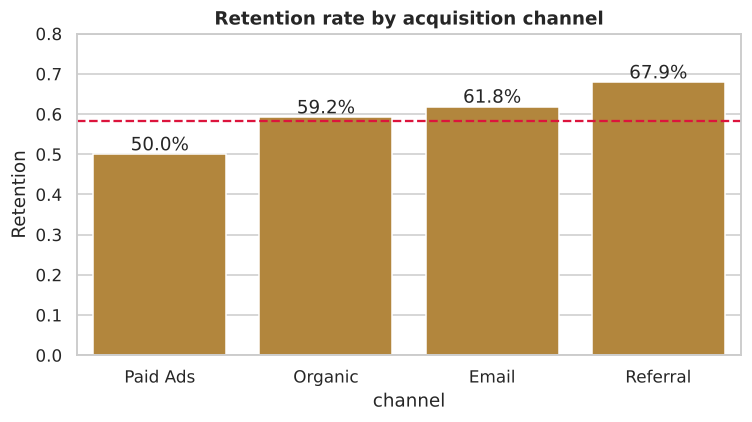

In [10]:
ct = pd.crosstab(df.channel, df.retained)
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2/(ct.values.sum()*(min(ct.shape)-1)))
print(f"chi2 = {chi2:.2f}, dof = {dof}, p = {p:.2e}, Cramér's V = {cramers_v:.3f}")
by_ch = df.groupby("channel").retained.agg(["mean","count"]).sort_values("mean")
print(by_ch.round(3))
fig, ax = plt.subplots(figsize=(7,4))
sns.barplot(x=by_ch.index, y=by_ch["mean"], color="#C58B2A", ax=ax)
for i,v in enumerate(by_ch["mean"]): ax.text(i, v+0.01, f"{v:.1%}", ha="center")
ax.axhline(df.retained.mean(), color="crimson", ls="--"); ax.set_ylim(0,0.8)
ax.set_title("Retention rate by acquisition channel"); ax.set_ylabel("Retention"); plt.tight_layout(); plt.show()

**Result:** reject H₀ (p < 0.001). Referral customers retain best and Paid Ads customers worst, a gap of roughly 18 percentage points. Effect size is small-to-moderate, but commercially meaningful because Paid Ads is also a major acquisition source.

### H3: More support tickets lead to lower satisfaction
- **H₀:** no monotonic relationship between tickets and satisfaction
- **H₁:** a monotonic (negative) relationship exists
- **Test:** Spearman rank correlation (tickets are count data, satisfaction is bounded)

Spearman rho = -0.397, p = 8.46e-75  (n = 1960)
                  mean  count
tickets (4 = 4+)             
0                 4.06    568
1                 3.77    683
2                 3.53    433
3                 3.26    178
4                 2.91     98


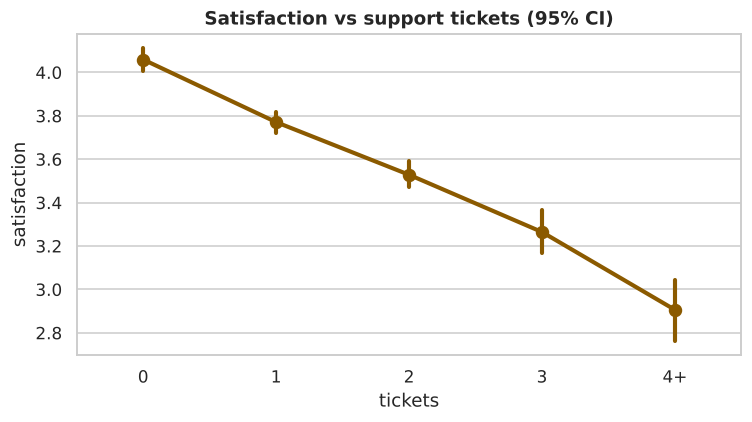


Satisfaction: retained 3.79 vs churned 3.61  (Mann-Whitney p = 4.0e-07)


In [11]:
d = df.dropna(subset=["satisfaction"])
rho, p = stats.spearmanr(d.support_tickets, d.satisfaction)
print(f"Spearman rho = {rho:.3f}, p = {p:.2e}  (n = {len(d)})")
print(d.groupby(d.support_tickets.clip(upper=4)).satisfaction.agg(["mean","count"]).round(2).rename_axis("tickets (4 = 4+)"))
fig, ax = plt.subplots(figsize=(7,4))
sns.pointplot(data=d.assign(tickets=d.support_tickets.clip(upper=4)), x="tickets", y="satisfaction", color="#8B5A00", errorbar=("ci",95), ax=ax)
ax.set_xticklabels(["0","1","2","3","4+"]); ax.set_title("Satisfaction vs support tickets (95% CI)"); plt.tight_layout(); plt.show()

# does satisfaction in turn matter for retention?
u = stats.mannwhitneyu(d[d.retained==1].satisfaction, d[d.retained==0].satisfaction)
print(f"\nSatisfaction: retained {d[d.retained==1].satisfaction.mean():.2f} vs churned {d[d.retained==0].satisfaction.mean():.2f}  (Mann-Whitney p = {u.pvalue:.1e})")

**Result:** reject H₀ (ρ ≈ −0.40, p < 0.001). Each extra ticket is associated with a clear drop in satisfaction, and satisfied customers are significantly more likely to stay. Tickets influence retention **indirectly through satisfaction**, not directly (ticket count is non-significant once satisfaction is in the regression).

## 5. Top 5 critical findings

| # | Finding | Evidence | Business action |
|---|---------|----------|-----------------|
| 1 | **Discounts do not drive retention** | Mean discount 9.8% for both retained and churned; t-test p = 0.94; non-significant in logistic model | Cap blanket discounts; reallocate budget to targeted offers |
| 2 | **Tenure and satisfaction are the real retention levers** | Both p < 0.001 in the logistic regression (each month of tenure ≈ +3% odds; each satisfaction point ≈ +43% odds) | Invest in onboarding and the first 6 months; track CSAT as an early-warning metric |
| 3 | **Paid Ads customers churn most** | Retention 50.0% vs Referral 67.9%, Email 61.8%, Organic 59.2%; χ² p < 0.001 | Shift spend toward referral and email programmes; review Paid Ads targeting quality |
| 4 | **Support friction erodes satisfaction** | Spearman ρ ≈ −0.40 between tickets and satisfaction | Fix top ticket drivers; proactive outreach after a customer's 2nd ticket |
| 5 | **Spend is highly skewed; Premium is the value engine** | Median spend ≈ $77 vs mean ≈ $100; 12 extreme spenders up to ~$1,650; Premium median ≈ 4x Budget and Premium retention 68% vs 55-56% | Report medians, not means; build VIP retention for the Premium tier and review extreme accounts for data errors |

**Caveats:** the data is synthetic, so effect sizes illustrate the method rather than a real business. Associations are observational, not causal. Re-run on real customer data by swapping the dataset cell for `pd.read_csv(...)` with the same column names.

In [12]:
df.drop(columns="discount_band").to_csv("customers_synthetic.csv", index=False)
print("Saved customers_synthetic.csv")

Saved customers_synthetic.csv


---
*rithicoded · EDA notebook*